# Tiền xử lý REFIT và thiết kế đánh giá theo từng hộ

Dùng chung cho NILMFormer và TwoStageNILMFormer. Thiết kế hiện tại chia **theo thời gian trong mỗi hộ**: 80% đầu train, 20% cuối test. Tạo hai nhánh thực nghiệm: một mô hình chung học phần train của mọi hộ và một mô hình riêng cho mỗi hộ. Cả hai nhánh đánh giá trên cùng phần test của từng hộ.

Đây là đánh giá thời gian tương lai của hộ đã xuất hiện trong train, **không phải đánh giá hộ chưa thấy**. Notebook chỉ xuất train/test 80/20. Runner TwoStage tách thêm validation bên trong 80% đầu để early stopping; mặc định xấp xỉ 64/16/20. Đánh giá checkpoint validation tốt nhất, không dùng test chọn epoch.

Giữ các bước xử lý tín hiệu của [mã NILMFormer](https://github.com/EDF-Lab/NILMFormer/blob/e73a975a42fbebed6f9d7e90d75f7f48ae02fed9/src/helpers/preprocessing.py): lưới 10 giây, forward-fill tối đa 90 giây, công suất dưới 5 W về 0, clip tối đa 10000 W, tạo trạng thái trước khi giảm về 1 phút. Scaling cố định `/10000` theo [bài báo](https://arxiv.org/html/2506.05880v1#S5.SS1.SSS3); bài ghi giới hạn điền 3 phút, khác code 90 giây. Cửa sổ 128 không chồng lấn và 8 đặc trưng TimeRPE theo mã.

Bản trước chỉ lấy giao danh sách đủ bốn nhãn theo cấu hình tác giả nên còn sáu hộ. Thiết kế mới xét mọi CSV hộ hiện có, không lọc theo danh sách thực nghiệm từng thiết bị của tác giả. Các kênh không ánh xạ được có `valid=False`; giá trị 0 lưu trong tensor chỉ là giá trị thay thế và không được dùng làm nhãn tắt. Không tự gộp các thiết bị có hậu tố hoặc thiết bị kết hợp thành một loại. PLEGMA cần pipeline riêng.

Schema REFIT cleaned có chín cổng `Appliance1`–`Appliance9` cố định, nhưng thiết bị tương ứng và độ phủ nhãn khác nhau. Ánh xạ tác giả được nhúng để truy vết; có chênh lệch với README nguồn, đặc biệt hộ 15. Kết quả trên kênh chưa xác minh cần được diễn giải cùng bảng inventory.

In [1]:
import hashlib
import json
import re
import sys
from io import StringIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

# Tìm project khi mở notebook từ thư mục gốc, data hoặc data/scripts.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data/cleaned/REFIT").is_dir()), None)
assert ROOT is not None, "Không tìm thấy thư mục dữ liệu REFIT trong project."
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [ ]:
from training.seeds import BASE_SEED, generate_model_seeds, make_data_generator, seed_everything, seed_worker

seed_everything(BASE_SEED)
CONFIG = {
    "dataset": "REFIT",
    "storage_format": "csv",
    "stored_power_unit": "W",
    "targets": ["WashingMachine", "Dishwasher", "Kettle", "Microwave"],
    "base_seed": BASE_SEED,
    "sampling_seconds": 60,
    "window_size": 128,
    "window_stride": 128,
    "power_scale_w": 10000.0,
    "clip_w": 10000.0,
    "small_power_w": 5.0,
    "ffill_10s_steps": 9,
    "train_time_fraction": 0.8,
    "study_design": "pooled_and_per_house_temporal_80_20",
    "missing_channel_policy": "masked_unmapped_channels",
    "upstream_commit": "e73a975a42fbebed6f9d7e90d75f7f48ae02fed9",
    "timestamp_basis": "Time trong bản cleaned, giữ như mã công bố; không tự gắn UTC",
}
PARAMETERS = {
    "WashingMachine": (300.0, 4000.0),
    "Dishwasher": (300.0, 4000.0),
    "Kettle": (500.0, 6000.0),
    "Microwave": (200.0, 6000.0),
}
PAPER_HOUSES = {
    "WashingMachine": [1, 2, 3, 5, 6, 7, 8, 9, 10, 13, 15, 16, 17, 18, 19],
    "Dishwasher": [1, 2, 3, 5, 6, 7, 9, 10, 13, 15, 16, 18, 20],
    "Kettle": [2, 3, 4, 5, 6, 7, 9, 12, 13, 15, 19, 20],
    "Microwave": [2, 3, 4, 6, 8, 9, 10, 12, 13, 15, 17, 18, 19, 20],
}
# Cố định đúng bốn loại và thứ tự kênh theo phạm vi nghiên cứu đã chốt.
assert CONFIG["targets"] == ["WashingMachine", "Dishwasher", "Kettle", "Microwave"], "Phải dùng đúng bốn thiết bị và thứ tự kênh đã chốt."
assert set(CONFIG["targets"]) <= PARAMETERS.keys(), "Thiết bị chưa có cấu hình ngưỡng."
assert CONFIG["window_stride"] == CONFIG["window_size"], "Pipeline này yêu cầu cửa sổ không chồng lấn."
assert CONFIG["sampling_seconds"] == 60, "Pipeline này đang tái lập REFIT ở nhịp 1 phút."
SOURCE_DIR = ROOT / "data/cleaned/REFIT"
config_id = hashlib.sha256(json.dumps(CONFIG, sort_keys=True).encode("utf-8")).hexdigest()[:12]
OUTPUT_DIR = ROOT / "data/processed/REFIT" / f"temporal_{config_id}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Thư mục kết quả:", OUTPUT_DIR)
print("Seed khởi tạo mô hình:", generate_model_seeds())
display(pd.DataFrame(CONFIG.items(), columns=["Thiết lập", "Giá trị"]))

## 1. Kiểm kê toàn bộ hộ và giải thích lựa chọn cũ

Bảng nguồn được nhúng để chạy ngoại tuyến. Bảng inventory đặt nhãn tác giả và mô tả README cạnh nhau. Các tên khớp chính xác được đưa vào kênh đích; tên có hậu tố, thiết bị kết hợp hoặc cổng chưa rõ giữ trạng thái chưa ánh xạ, không tự suy thành tắt.

Danh sách hộ theo từng thiết bị trong cấu hình tác giả chỉ phục vụ giải thích tại sao bản trước chọn sáu hộ. Pipeline mới **không dùng danh sách đó để loại hộ**. Một hộ chỉ không thể huấn luyện khi không có bất kỳ nhãn đích nào hoặc không còn cửa sổ hợp lệ, và phải được ghi rõ.

In [3]:
UPSTREAM_LABELS = (
    "House_id,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9,Issues\n1,Time,Unix,Agg"
    "regate,Fridge,Chest Freezer,Upright Freezer,TumbleDryer,WashingMachine,Dishwasher,ComputerSite,TelevisionSite,ElectricHeater,Issues\n2,Time,Unix,Aggreg"
    "ate,Fridge-Freezer,WashingMachine,Dishwasher,TelevisionSite,Microwave,Toaster,Hi-Fi,Kettle,Oven Extractor Fan,Issues\n3,Time,Unix,Aggregate,Toaster,Fri"
    "dge-Freezer,Freezer,TumbleDryer,Dishwasher,WashingMachine,TelevisionSite,Microwave,Kettle,Issues\n4,Time,Unix,Aggregate,Fridge,Freezer,Fridge-Freezer,W"
    "ashingMachine (1),WashingMachine (2),ComputerSite,TelevisionSite,Microwave,Kettle,Issues\n5,Time,Unix,Aggregate,Fridge-Freezer,TumbleDryer,WashingMachi"
    "ne,Dishwasher,ComputerSite,TelevisionSite,Combination Microwave,Kettle,Toaster,Issues\n6,Time,Unix,Aggregate,Freezer,WashingMachine,Dishwasher,MJY Comp"
    "uter,TelevisionSite,Microwave,Kettle,Toaster,PGM Computer,Issues\n7,Time,Unix,Aggregate,Fridge,Freezer (garage),Freezer,TumbleDryer,WashingMachine,Dish"
    "washer,TelevisionSite,Television,Kettle,Issues\n8,Time,Unix,Aggregate,Fridge,Freezer,TumbleDryer,WashingMachine,Toaster,Computer,TelevisionSite,Microwa"
    "ve,Kettle,Issues\n9,Time,Unix,Aggregate,Fridge-Freezer,Washer Dryer,WashingMachine,Dishwasher,TelevisionSite,Microwave,Kettle,Hi-Fi,ElectricHeater,Issu"
    "es\n10,Time,Unix,Aggregate,Magimix (Blender),Freezer,Chest Freezer (In Garage),Fridge-Freezer,WashingMachine,Dishwasher,TelevisionSite,Microwave,Kenwoo"
    "d KMix,Issues\n11,Time,Unix,Aggregate,Fridge,Fridge-Freezer,WashingMachine,Dishwasher,ComputerSite,Microwave,Kettle,Router,Hi-Fi,Issues\n12,Time,Unix,Ag"
    "gregate,Fridge-Freezer,TelevisionSite(Lounge),Microwave,Kettle,Toaster,TelevisionSite(Bedroom),Not Used,Not Used,Not Used,Issues\n13,Time,Unix,Aggregat"
    "e,TelevisionSite,Unknown,WashingMachine,Dishwasher,TumbleDryer,TelevisionSite,ComputerSite,Microwave,Kettle,Issues\n15,Time,Unix,Aggregate,Fridge-Freez"
    "er,TumbleDryer,WashingMachine,Dishwasher,ComputerSite,TelevisionSite,Microwave,Kettle,Toaster,Issues\n16,Time,Unix,Aggregate,Fridge-Freezer (1),Fridge-"
    "Freezer (2),ElectricHeater (1),ElectricHeater (2),WashingMachine,Dishwasher,ComputerSite,TelevisionSite,Dehumidifier/Heater,Issues\n17,Time,Unix,Aggreg"
    "ate,Freezer (Garage),Fridge-Freezer,TumbleDryer (Garage),WashingMachine,ComputerSite,TelevisionSite,Microwave,Kettle,Plug Site (Bedroom),Issues\n18,Tim"
    "e,Unix,Aggregate,Fridge(garage),Freezer(garage),Fridge-Freezer,Washer Dryer(garage),WashingMachine,Dishwasher,Desktop Computer,TelevisionSite,Microwav"
    "e,Issues\n19,Time,Unix,Aggregate,Fridge & Freezer,WashingMachine,TelevisionSite,Microwave,Kettle,Toaster,Bread-maker,Lamp (80Watts),Hi-Fi,Issues\n20,Tim"
    "e,Unix,Aggregate,Fridge,Freezer,TumbleDryer,WashingMachine,Dishwasher,ComputerSite,TelevisionSite,Microwave,Kettle,Issues\n21,Time,Unix,Aggregate,Fridg"
    "e-Freezer,TumbleDryer,WashingMachine,Dishwasher,Food Mixer,TelevisionSite,Kettle/Toaster,Vivarium,Pond Pump,Issues\n"
)
labels = pd.read_csv(StringIO(UPSTREAM_LABELS)).set_index("House_id")
source_notes = (ROOT / "data/raw/REFIT/CLEAN_READ_ME_081116.txt").read_text(encoding="utf-8-sig")
readme_mapping = {}
current_house = None
for line in source_notes.splitlines():
    house_match = re.fullmatch(r"House (\d+)", line.strip())
    if house_match:
        current_house = int(house_match.group(1))
    channel_match = re.match(r"([1-9])\.(.*)", line.strip())
    if current_house is not None and channel_match:
        readme_mapping[(current_house, f"Appliance{channel_match.group(1)}")] = channel_match.group(2).strip()

inventory_rows = []
channel_maps = {}
for path in sorted(SOURCE_DIR.glob("CLEAN_House*.csv")):
    house = int(re.search(r"House(\d+)", path.name).group(1))
    header = pd.read_csv(path, nrows=0).columns.tolist()
    expected = ["Time", "Unix", "Aggregate", *[f"Appliance{i}" for i in range(1, 10)], "Issues"]
    assert header == expected, f"Header không đúng schema cleaned REFIT ở hộ {house}."
    assert house in labels.index, f"Hộ {house} chưa có ánh xạ nguồn."
    channel_maps[house] = {}
    for channel in expected[3:-1]:
        name = labels.loc[house, channel]
        if name in CONFIG["targets"]:
            assert name not in channel_maps[house], f"Có nhiều cổng cùng thiết bị {name} tại hộ {house}; cần chốt chính sách gộp."
            channel_maps[house][name] = channel
        inventory_rows.append(
            {
                "house": house,
                "channel": channel,
                "upstream_label": name,
                "readme_description": readme_mapping.get((house, channel), "Không có mô tả"),
                "selected_target": name if channel_maps[house].get(name) == channel else "",
            }
        )
inventory = pd.DataFrame(inventory_rows)
display(inventory)
# Bảng đặt cạnh nhau giúp kiểm tra khác biệt ngữ nghĩa, không chỉ khác cách viết.
display(inventory[inventory["house"].isin([5, 7, 12, 13, 21])])
inventory.to_csv(OUTPUT_DIR / "channel_inventory.csv", index=False, encoding="utf-8-sig")
availability = pd.DataFrame([{"house": house, **{name: name in mapping for name in CONFIG["targets"]}} for house, mapping in sorted(channel_maps.items())])
# Tái hiện bộ lọc cũ: phải thuộc mọi danh sách thực nghiệm và đủ mọi nhãn.
old_complete_houses = sorted(h for h, mapping in channel_maps.items() if all(name in mapping and h in PAPER_HOUSES[name] for name in CONFIG["targets"]))
houses = sorted(channel_maps)
assert all(channel_maps[house] for house in houses), "Có hộ chưa ánh xạ được bất kỳ thiết bị đích nào; cần xử lý trước khi train."
print("Các hộ được xét trong thiết kế mới:", houses)
print("Nhóm đủ bốn nhãn theo bộ lọc cũ:", old_complete_houses)
print("Thứ tự kênh đích cố định:", CONFIG["targets"])
display(availability)
availability.to_csv(OUTPUT_DIR / "channel_availability.csv", index=False, encoding="utf-8-sig")

,house,channel,upstream_label,readme_description,selected_target
0,1,Appliance1,Fridge,"Fridge, Hotpoint, RLA50P",
1,1,Appliance2,Chest Freezer,"Freezer(1),Beko, CF393APW",
2,1,Appliance3,Upright Freezer,"Freezer(2), Unknown, Unknown",
3,1,Appliance4,TumbleDryer,"Washer Dryer, Creda, T522VW",
4,1,Appliance5,WashingMachine,"Washing Machine, Beko, WMC6140",WashingMachine
...,...,...,...,...,...
175,9,Appliance5,TelevisionSite,"Television Site, LG, 32LH3000",
176,9,Appliance6,Microwave,"Microwave, Argos, MM717CFA",Microwave
177,9,Appliance7,Kettle,"Kettle, Russel Hobbs, Unknown",Kettle
178,9,Appliance8,Hi-Fi,"Hi-Fi, Unknown, Unknown",


,house,channel,upstream_label,readme_description,selected_target
27,12,Appliance1,Fridge-Freezer,"Fridge-Freezer, Gorenje, HZS 3266",
28,12,Appliance2,TelevisionSite(Lounge),"???, Unknown, Unknown",
29,12,Appliance3,Microwave,"???, Unknown, Unknown",Microwave
30,12,Appliance4,Kettle,"Computer Site, Unknown, Unknown",Kettle
31,12,Appliance5,Toaster,"Microwave, Unknown, Unknown",
32,12,Appliance6,TelevisionSite(Bedroom),"Kettle, Unknown, Unknown",
33,12,Appliance7,Not Used,"Toaster, Unknown, Unknown, (Nothing Recorded)",
34,12,Appliance8,Not Used,"Television, Unknown, Unknown, (Nothing Recorded)",
35,12,Appliance9,Not Used,"???, Unknown, Unknown, (Nothing Recorded)",
36,13,Appliance1,TelevisionSite,"Television Site, Samsung, UE55H6400AK",


Các hộ được xét trong thiết kế mới: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 15, 16, 17, 18, 19, 20, 21]
Nhóm đủ bốn nhãn theo bộ lọc cũ: [2, 3, 6, 9, 13, 15]
Thứ tự kênh đích cố định: ['WashingMachine', 'Dishwasher', 'Kettle', 'Microwave']


,house,WashingMachine,Dishwasher,Kettle,Microwave
0,1,True,True,False,False
1,2,True,True,True,True
2,3,True,True,True,True
3,4,False,False,True,True
4,5,True,True,True,False
5,6,True,True,True,True
6,7,True,True,True,False
7,8,True,False,True,True
8,9,True,True,True,True
9,10,True,True,False,True


## 2. Quy tắc chia thời gian, không chia ngẫu nhiên cửa sổ

Với từng hộ, lấy khoảng từ phút chứa timestamp đầu đến cuối phút chứa timestamp cuối, chia tại mốc 80% thời lượng và làm tròn mốc lên phút. Dòng trước mốc thuộc train, từ mốc trở đi thuộc test. Đây là tỷ lệ **thời gian lịch**, không phải 80% số cửa sổ sau lọc; tỷ lệ dữ liệu hợp lệ có thể khác 80/20 vì mất dữ liệu.

Tách dữ liệu gốc trước forward-fill/resample và xử lý hai phần độc lập. Không điền qua ranh giới train/test; không có cửa sổ cắt ngang ranh giới. Khoảng mất dữ liệu vẫn nằm trên lưới thời gian. Không lấy dữ liệu tương lai cho train.

In [4]:
def split_by_time(frame):
    timestamp = pd.to_datetime(frame["Time"], errors="coerce")
    assert timestamp.notna().all() and len(frame) > 0, "Timestamp không hợp lệ hoặc hộ không có dữ liệu."
    start = timestamp.min().floor("min")
    end_exclusive = timestamp.max().floor("min") + pd.Timedelta(minutes=1)
    boundary = (start + (end_exclusive - start) * CONFIG["train_time_fraction"]).ceil("min")
    assert start < boundary < end_exclusive, "Khoảng thời gian quá ngắn để chia train/test."
    parts = {"train": frame.loc[timestamp < boundary].copy(), "test": frame.loc[timestamp >= boundary].copy()}
    assert all(not part.empty for part in parts.values()), "Một phần train/test không có dữ liệu."
    metadata = {"start": str(start), "train_end_exclusive": str(boundary), "test_start": str(boundary), "end_exclusive": str(end_exclusive)}
    return parts, metadata


print("Chia thời gian riêng trong từng hộ với tỷ lệ:", CONFIG["train_time_fraction"])

Chia thời gian riêng trong từng hộ với tỷ lệ: 0.8


## 3. Hàm xử lý và cửa sổ có mask kênh thiếu

Mỗi phần train/test được xử lý độc lập theo thứ tự đã nêu. Chỉ loại cửa sổ khi điện tổng hoặc **kênh đã ánh xạ** còn NaN/Inf. Kênh chưa ánh xạ được lưu 0 với `valid=False` ở toàn bộ thời gian; không loại cả hộ và không gán nhãn tắt cho kênh đó.

Nhãn bật/tắt được tạo ở 10 giây; một phút bật nếu có ít nhất một mẫu bật. Số thiết bị bật đồng thời chỉ đếm các kênh đích có nhãn. Bản cleaned nguồn đã được xử lý trước đó; số ô điền thêm không phản ánh toàn bộ mức nội suy của dataset.

In [5]:
def preprocess_frame(frame, mapping):
    targets = CONFIG["targets"]
    frame = frame.copy()
    timestamp = pd.to_datetime(frame["Time"], errors="coerce")
    assert timestamp.notna().all(), "Có timestamp không đọc được."
    statistics = {"raw_rows": len(frame), "duplicate_timestamps": int(timestamp.duplicated().sum()), "issues_rows": int(frame["Issues"].eq(1).sum())}
    frame.index = pd.DatetimeIndex(timestamp)
    frame = frame.loc[frame["Issues"].ne(1), ["Aggregate", *list(mapping.values())]].sort_index()
    frame = frame.rename(columns={channel: name for name, channel in mapping.items()}).astype("float64")
    frame = frame.replace([np.inf, -np.inf], np.nan)
    assert not frame.empty, "Không còn dữ liệu sau khi loại cờ Issues."
    grid = frame.resample("10s").mean()
    missing_before = grid.isna()
    filled = grid.ffill(limit=CONFIG["ffill_10s_steps"])
    statistics["ffill_cells_added"] = int((missing_before & filled.notna()).to_numpy().sum())
    statistics["grid_10s_rows"] = len(grid)
    filled = filled.mask(filled < CONFIG["small_power_w"], 0).clip(lower=0, upper=CONFIG["clip_w"])
    for name in targets:
        if name not in filled:
            filled[name] = np.nan
    state = pd.DataFrame(index=filled.index)
    for name in targets:
        lower, upper = PARAMETERS[name]
        # Giữ NaN tại nhãn thiếu; không biến nhãn thiếu thành trạng thái tắt.
        state[name] = filled[name].between(lower, upper).astype("float64").where(filled[name].notna())
    minute_power = filled.resample("1min").mean()
    minute_state_fraction = state.resample("1min").mean()
    minute_on = minute_state_fraction.gt(0).astype("float64").where(minute_state_fraction.notna())
    return minute_power, minute_on, statistics


def time_features(index):
    # L timestamp → (8, L), gồm sin/cos của phút, giờ, thứ trong tuần và tháng.
    values = [index.minute.to_numpy(), index.hour.to_numpy(), index.day_of_week.to_numpy(), index.month.to_numpy()]
    periods = [60.0, 24.0, 7.0, 12.0]
    return np.stack([function(2 * np.pi * value / period) for value, period in zip(values, periods, strict=True) for function in (np.sin, np.cos)]).astype("float32")


def make_windows(power, on, available_targets=None):
    length = CONFIG["window_size"]
    channels = len(CONFIG["targets"])
    available_targets = CONFIG["targets"] if available_targets is None else available_targets
    available = np.array([name in available_targets for name in CONFIG["targets"]], dtype=bool)
    assert available.any(), "Không có kênh đích đã ánh xạ để tạo cửa sổ."
    n_candidates = len(power) // length
    usable = n_candidates * length
    # (T, 1 + C) → (N, L, 1 + C) → (N, 1 + C, L); không trộn giữa các hộ.
    values = power[["Aggregate", *CONFIG["targets"]]].iloc[:usable].to_numpy(dtype="float32").reshape(n_candidates, length, 1 + channels).transpose(0, 2, 1)
    states = on[CONFIG["targets"]].iloc[:usable].to_numpy(dtype="float32").reshape(n_candidates, length, channels).transpose(0, 2, 1)
    keep = np.isfinite(values[:, 0]).all(axis=1)
    keep &= (np.isfinite(values[:, 1:]) | ~available[None, :, None]).all(axis=(1, 2))
    keep &= (np.isfinite(states) | ~available[None, :, None]).all(axis=(1, 2))
    # Chuỗi chỉ số khởi đầu giúp giữ timestamp đúng sau khi loại cửa sổ thiếu.
    window_start = np.arange(n_candidates)[keep] * length
    values, states = values[keep], states[keep]
    # Chỉ thay thế NaN ở kênh chưa ánh xạ; mask sẽ loại các giá trị thay thế khỏi loss/metrics.
    values[:, 1:] = np.where(available[None, :, None], values[:, 1:], 0)
    states = np.where(available[None, :, None], states, 0).astype("float32")
    encoding = time_features(power.index[:usable]).reshape(8, n_candidates, length).transpose(1, 0, 2)[keep]
    # Điện tổng (N, 1, L) + thời gian (N, 8, L) → x (N, 9, L).
    x = np.concatenate([values[:, :1] / CONFIG["power_scale_w"], encoding], axis=1)
    target_power = values[:, 1:] / CONFIG["power_scale_w"]  # (N, C, L), tắt vẫn bằng 0.
    valid = np.broadcast_to(available[None, :, None], states.shape).copy()
    payload = {
        "x": x.astype("float32"),
        "power": target_power.astype("float32"),
        "on": states.astype("float32"),
        "valid": valid,
        "start_time_ns": power.index[window_start].to_numpy(dtype="datetime64[ns]").astype("int64"),
        "active_count": states.sum(axis=1).astype("uint8"),  # (N, C, L) → (N, L): số thiết bị đích bật.
    }
    stats = {"minute_rows": len(power), "candidate_windows": n_candidates, "kept_windows": int(keep.sum()), "dropped_windows": int((~keep).sum()), "tail_minutes_dropped": len(power) - usable}
    return payload, stats


def write_csv_windows(payload, output_path, house):
    windows, _, length = payload["x"].shape
    # Mỗi dòng là một phút; window_id và step giữ đúng ranh giới sau khi loại cửa sổ thiếu.
    timestamp_ns = (payload["start_time_ns"][:, None] + np.arange(length)[None, :] * 60 * 10**9).reshape(-1)
    table = pd.DataFrame(
        {
            "house_id": house,
            "window_id": np.repeat(np.arange(windows), length),
            "step": np.tile(np.arange(length), windows),
            "timestamp": pd.to_datetime(timestamp_ns),
            "aggregate_w": (payload["x"][:, 0] * CONFIG["power_scale_w"]).reshape(-1),
        }
    )
    for channel, name in enumerate(CONFIG["targets"]):
        mask = payload["valid"][:, channel].reshape(-1)
        # (N, C, L) → (N * L,); trả về W trước khi ghi, ô thiếu nhãn để trống.
        power_w = (payload["power"][:, channel] * CONFIG["power_scale_w"]).reshape(-1)
        table[f"{name}_w"] = np.where(mask, power_w, np.nan)
        table[f"{name}_on"] = np.where(mask, payload["on"][:, channel].reshape(-1), np.nan)
        table[f"{name}_valid"] = mask.astype("uint8")
    table["active_target_devices"] = payload["active_count"].reshape(-1)
    table.to_csv(output_path, index=False, encoding="utf-8", float_format="%.9g", date_format="%Y-%m-%d %H:%M:%S")

## 4. Kiểm tra nhãn, khoảng thiếu, mask và ranh giới thời gian

Kiểm tra chuỗi có đáp án biết trước: nhãn được tạo trước giảm nhịp, không điền vô hạn, loại cửa sổ thiếu ở kênh đã ánh xạ, giữ cửa sổ khi chỉ thiếu kênh chưa ánh xạ và không trộn thời gian train/test.

In [6]:
test_index = pd.date_range("2023-01-01", periods=12, freq="10s")
test_frame = pd.DataFrame({"Time": test_index, "Issues": 0, "Aggregate": 3000.0})
test_mapping = {name: name for name in CONFIG["targets"]}
for name in CONFIG["targets"]:
    test_frame[name] = 0.0
test_frame.loc[1, "Kettle"] = 2000.0
minute_power, minute_on, _ = preprocess_frame(test_frame, test_mapping)
assert minute_power.iloc[0]["Kettle"] < PARAMETERS["Kettle"][0], "Chuỗi kiểm tra chưa tạo được mức trung bình dưới ngưỡng."
assert minute_on.iloc[0]["Kettle"] == 1, "Nhãn phải được tạo trước khi giảm nhịp."
# Khoảng thiếu dài không được forward-fill vô hạn.
gap_frame = test_frame.iloc[[0, -1]].copy()
gap_power, _, _ = preprocess_frame(gap_frame, test_mapping)
assert gap_power.iloc[1]["Aggregate"] == 3000, "Điểm cuối chuỗi phải được giữ."
long_gap = test_frame.iloc[[0, -1]].copy()
long_gap.loc[long_gap.index[-1], "Time"] = test_index[0] + pd.Timedelta(minutes=10)
long_power, _, _ = preprocess_frame(long_gap, test_mapping)
assert long_power.iloc[5].isna().all(), "Khoảng thiếu dài không được lấp đầy."
length = CONFIG["window_size"]
window_index = pd.date_range("2023-01-01", periods=2 * length, freq="1min")
check_power = pd.DataFrame(100.0, index=window_index, columns=["Aggregate", *CONFIG["targets"]])
check_on = pd.DataFrame(0.0, index=window_index, columns=CONFIG["targets"])
check_power.iloc[length + 1, 0] = np.nan
check_payload, check_stats = make_windows(check_power, check_on)
assert check_payload["x"].shape == (1, 9, length), "Chiều input không đúng."
assert check_payload["power"].shape == (1, len(CONFIG["targets"]), length), "Chiều target không đúng."
assert check_stats["dropped_windows"] == 1, "Phải loại cửa sổ có NaN."
assert np.allclose(check_payload["power"], 100 / CONFIG["power_scale_w"]), "Scaling không đúng."
assert check_payload["start_time_ns"][0] == window_index[0].value, "Timestamp đầu cửa sổ bị sai."
print("Các kiểm tra thuật toán đều đạt.")
# Thiết bị không được ánh xạ phải bị mask, không bị dùng như một nhãn tắt.
masked_power = check_power.copy()
masked_power["Kettle"] = np.nan
masked_on = check_on.copy()
masked_on["Kettle"] = np.nan
available_targets = [name for name in CONFIG["targets"] if name != "Kettle"]
masked_payload, _ = make_windows(masked_power, masked_on, available_targets)
kettle_index = CONFIG["targets"].index("Kettle")
assert not masked_payload["valid"][:, kettle_index].any(), "Kênh chưa ánh xạ phải bị mask toàn bộ."
assert masked_payload["power"].shape[0] == 1, "Kênh chưa ánh xạ không được làm mất cửa sổ hợp lệ."
synthetic_frame = pd.DataFrame({"Time": pd.date_range("2023-01-01", periods=1000, freq="1min")})
parts, boundary_metadata = split_by_time(synthetic_frame)
assert len(parts["train"]) == 800 and len(parts["test"]) == 200, "Chia thời gian chưa đúng 80/20."
assert parts["train"]["Time"].max() < parts["test"]["Time"].min(), "Train và test bị chồng thời gian."
print("Kiểm tra mask kênh thiếu và ranh giới thời gian đều đạt.")

Các kiểm tra thuật toán đều đạt.
Kiểm tra mask kênh thiếu và ranh giới thời gian đều đạt.


## 5. Xuất CSV theo hộ và tập train/test

Mỗi hộ được đọc riêng và chia thời gian trước xử lý. Xuất một file CSV cho mỗi hộ/tập trong `data/processed/REFIT/temporal_<mã cấu hình>/`. Mỗi dòng là một mẫu một phút của một cửa sổ đã giữ lại, gồm:

- `house_id`, `window_id`, `step`, `timestamp` để giữ hộ, ranh giới cửa sổ và thứ tự thời gian.
- `aggregate_w` và bốn cột `<thiết bị>_w`: công suất **W, chưa normalize**.
- `<thiết bị>_on` và `<thiết bị>_valid`: nhãn bật/tắt và mask hợp lệ.
- `active_target_devices`: số kênh mục tiêu đang bật có nhãn.

Kênh không có nhãn để trống công suất và trạng thái, với valid=0. Không dùng dropna trên mọi cột khi load, vì sẽ loại cả hộ thiếu một thiết bị. Tám đặc trưng TimeRPE được tạo từ timestamp khi load, không lưu lặp lại trong CSV. Manifest giữ hệ số normalize cố định 10000 và thứ tự kênh. Chạy lại sẽ ghi lại các file đã sinh trong đúng thư mục cấu hình.

In [ ]:
house_rows, device_rows, overlap_rows, manifest_shards = [], [], [], []
time_splits = {}
example = None
for house in tqdm(houses, desc="Xử lý toàn bộ hộ theo thời gian", unit="hộ"):
    mapping = channel_maps[house]
    source_path = SOURCE_DIR / f"CLEAN_House{house}.csv"
    frame = pd.read_csv(source_path, usecols=["Time", "Issues", "Aggregate", *list(mapping.values())])
    parts, boundary_metadata = split_by_time(frame)
    time_splits[str(house)] = boundary_metadata
    del frame
    for split_name, part in parts.items():
        minute_power, minute_on, raw_stats = preprocess_frame(part, mapping)
        payload, window_stats = make_windows(minute_power, minute_on, mapping.keys())
        # Timestamp cửa sổ chỉ thuộc một phía của mốc 80%; kiểm tra cả điểm cuối.
        boundary_ns = pd.Timestamp(boundary_metadata["test_start"]).value
        if split_name == "train":
            assert ((payload["start_time_ns"] + (CONFIG["window_size"] - 1) * 60 * 10**9) < boundary_ns).all(), "Cửa sổ train vượt ranh giới test."
        else:
            assert (payload["start_time_ns"] >= boundary_ns).all(), "Cửa sổ test chứa thời gian train."
        shard_path = OUTPUT_DIR / f"{split_name}_house_{house:02d}.csv"
        write_csv_windows(payload, shard_path, house)
        house_rows.append(
            {
                "house": house,
                "split": split_name,
                "observed_target_channels": len(mapping),
                "start_time": str(minute_power.index.min()),
                "end_time": str(minute_power.index.max()),
                **raw_stats,
                **window_stats,
            }
        )
        for channel, name in enumerate(CONFIG["targets"]):
            observed = name in mapping
            retained_mask = payload["valid"][:, channel]
            retained_power = payload["power"][:, channel][retained_mask] * CONFIG["power_scale_w"]
            observed_on = minute_on[name].where(minute_power[name].notna())
            device_rows.append(
                {
                    "house": house,
                    "split": split_name,
                    "device": name,
                    "mapped": observed,
                    "source_channel": mapping.get(name, "Chưa ánh xạ"),
                    "valid_retained_minutes": int(retained_mask.sum()),
                    "missing_minute_fraction": float(minute_power[name].isna().mean()),
                    "on_fraction_retained": float(payload["on"][:, channel][retained_mask].mean()) if retained_mask.any() else np.nan,
                    "on_starts_before_window_filter": int((observed_on.eq(1) & observed_on.shift(1).eq(0)).sum()) if observed else np.nan,
                    "retained_energy_kwh": float(retained_power.astype("float64").sum() * 60 / 3_600_000) if retained_mask.any() else np.nan,
                }
            )
        counts = np.bincount(payload["active_count"].ravel(), minlength=len(CONFIG["targets"]) + 1)
        for active, count in enumerate(counts):
            overlap_rows.append({"house": house, "split": split_name, "observed_target_channels": len(mapping), "active_target_devices": active, "minutes": int(count)})
        manifest_shards.append(
            {
                "house": house,
                "split": split_name,
                "file": shard_path.name,
                "windows": len(payload["x"]),
                "source_file": str(source_path.relative_to(ROOT)),
                "source_bytes": source_path.stat().st_size,
                "source_mtime_ns": source_path.stat().st_mtime_ns,
                "channel_map": mapping,
            }
        )
        if example is None and split_name == "train" and len(payload["x"]):
            example = {"house": house, **{key: value[:1].copy() for key, value in payload.items()}}
        del minute_power, minute_on, payload
    del parts

house_report = pd.DataFrame(house_rows)
device_report = pd.DataFrame(device_rows)
overlap_report = pd.DataFrame(overlap_rows)
for filename, table in [("house_report.csv", house_report), ("device_report.csv", device_report), ("overlap_report.csv", overlap_report)]:
    table.to_csv(OUTPUT_DIR / filename, index=False, encoding="utf-8-sig")
split_path = OUTPUT_DIR / "split.json"
if split_path.exists():
    assert json.loads(split_path.read_text(encoding="utf-8")) == time_splits, "Mốc thời gian đã lưu không khớp dữ liệu hiện tại."
split_path.write_text(json.dumps(time_splits, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
manifest = {
    "config": CONFIG,
    "thresholds_w": PARAMETERS,
    "model_seeds": generate_model_seeds(),
    "time_splits": time_splits,
    "upstream_labels_sha256": hashlib.sha256(UPSTREAM_LABELS.encode("utf-8")).hexdigest(),
    "x_channels": ["Aggregate", "minute_sin", "minute_cos", "hour_sin", "hour_cos", "dow_sin", "dow_cos", "month_sin", "month_cos"],
    "target_channels": CONFIG["targets"],
    "shards": manifest_shards,
    "study_protocols": ["pooled_all_houses", "one_model_per_house"],
    "differences_from_paper": [
        "Chia thời gian 80/20 trong mỗi hộ thay vì giữ hộ test chưa thấy",
        "Nhiều đầu ra và mask kênh chưa ánh xạ",
        "Forward-fill 90 giây theo code",
        "5 seed khởi tạo trên cùng split",
    ],
    "checkpoint_selection": "Runner TwoStage tách validation bên trong train; chọn best.pt theo validation, không dùng test.",
}
(OUTPUT_DIR / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
(OUTPUT_DIR / "upstream_labels.csv").write_text(UPSTREAM_LABELS, encoding="utf-8")
# Cùng một seed khởi tạo được dùng cho hai mô hình và hai nhánh thiết kế để so sánh có ghép cặp.
study_runs = [
    {
        "model": model_name,
        "protocol": protocol,
        "model_seed": seed,
        "training_seed": BASE_SEED,
        "train_houses": houses if protocol == "pooled_all_houses" else [house],
        "evaluate_houses": houses if protocol == "pooled_all_houses" else [house],
        "epochs_selection": "early_stopping_on_validation_within_train" if model_name == "TwoStageNILMFormer" else "fixed_before_test",
    }
    for model_name in ["NILMFormer", "TwoStageNILMFormer"]
    for seed in generate_model_seeds()
    for protocol in ["pooled_all_houses", "one_model_per_house"]
    for house in ([None] if protocol == "pooled_all_houses" else houses)
]
(OUTPUT_DIR / "study_runs.json").write_text(json.dumps(study_runs, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
display(house_report)
display(device_report)
display(house_report.groupby("split")[["candidate_windows", "kept_windows", "dropped_windows"]].sum())
print("Số cấu hình thực nghiệm được lập kế hoạch:", len(study_runs))
print("Hộ/tập không có cửa sổ:", house_report.loc[house_report["kept_windows"].eq(0), ["house", "split"]].to_dict("records"))
print("Đã lưu manifest:", OUTPUT_DIR / "manifest.json")

## 6. Load CSV, normalize và kiểm tra hai mô hình

Lớp `REFITCSVDataset` trong `training/data.py` đọc CSV theo manifest, kiểm tra window_id/step/timestamp, thay ô thiếu bằng 0 sau khi đọc mask, chia điện tổng và công suất thiết bị cho 10000 rồi tạo 8 đặc trưng TimeRPE. Không fit scaler lên test. Có thể dùng `normalize=False` để nhận công suất W.

Dùng `house_id=None` để nạp mọi hộ, hoặc một ID để nạp riêng hộ đó. Batch đầu ra `x: (B, 9, L)`, `power/on/valid: (B, 4, L)`. Không resample, tạo lại nhãn hoặc chia lại thời gian trong train. Bộ nạp cache mỗi CSV sau lần đọc đầu để không đọc lại cả file khi shuffle; RAM tăng theo số hộ đã truy cập. Bắt đầu với num_workers=0.

Cell này chỉ kiểm tra một batch và forward cả hai mô hình nhỏ, không train.

In [8]:
from training.data import REFITCSVDataset
from training.model.NILMFormer.NILMFormer import NILMFormer, NILMFormerConfig
from training.model.TwoStageNILMFormer.GRUDetector import GRUConfig
from training.model.TwoStageNILMFormer.NILMFormerRegressor import NILMFormerConfig as RegressorConfig
from training.train_twostage_nilmformer import initialize_twostage_nilmformer

train_dataset = REFITCSVDataset(OUTPUT_DIR, "train")
test_dataset = REFITCSVDataset(OUTPUT_DIR, "test")
single_house_train = REFITCSVDataset(OUTPUT_DIR, "train", house_id=houses[0])
single_house_test = REFITCSVDataset(OUTPUT_DIR, "test", house_id=houses[0])
assert single_house_train.shards[0]["house"] == single_house_test.shards[0]["house"], "Bộ nạp riêng phải cùng một hộ."
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, generator=make_data_generator(BASE_SEED), worker_init_fn=seed_worker, num_workers=0)
batch = next(iter(train_loader))
print("Kích thước batch:", {key: tuple(value.shape) for key, value in batch.items()})
assert batch["x"].shape == (4, 9, CONFIG["window_size"]), "Shape input không khớp."
assert batch["power"].shape == (4, len(CONFIG["targets"]), CONFIG["window_size"]), "Shape target không khớp."

model_seed = generate_model_seeds()[0]
# Cấu hình nhỏ chỉ để kiểm tra kết nối pipeline và mô hình, không phải kết quả benchmark.
small = {"c_out": len(CONFIG["targets"]), "d_model": 16, "n_head": 4, "n_encoder_layers": 1, "dp_rate": 0}
two_stage = initialize_twostage_nilmformer(GRUConfig(c_out=len(CONFIG["targets"]), conv_channels=4, hidden=4), RegressorConfig(**small), model_seed).eval()
seed_everything(model_seed)
baseline = NILMFormer(NILMFormerConfig(**small)).eval()
with torch.no_grad():
    two_stage_output = two_stage(batch["x"])
    baseline_output = baseline(batch["x"])
assert two_stage_output.prediction.shape == baseline_output.shape == batch["power"].shape, "Hai mô hình không khớp shape target."
assert torch.isfinite(two_stage_output.prediction).all() and torch.isfinite(baseline_output).all(), "Forward có giá trị không hữu hạn."
print("Hai mô hình đều nhận được batch và trả công suất đúng shape.")

Kích thước batch: {'x': (4, 9, 128), 'power': (4, 4, 128), 'on': (4, 4, 128), 'valid': (4, 4, 128), 'house_id': (4,), 'start_time_ns': (4,)}


Hai mô hình đều nhận được batch và trả công suất đúng shape.


## 7. Minh họa cửa sổ và tải đồng thời

Chỉ vẽ các kênh có nhãn trong cửa sổ. Biểu đồ đồng thời đếm số kênh mục tiêu đang bật có quan sát được, không phải toàn bộ thiết bị trong nhà. Khi so mức đồng thời giữa các hộ, cần phân tầng theo số kênh có nhãn để tránh đánh đồng độ phủ cảm biến.

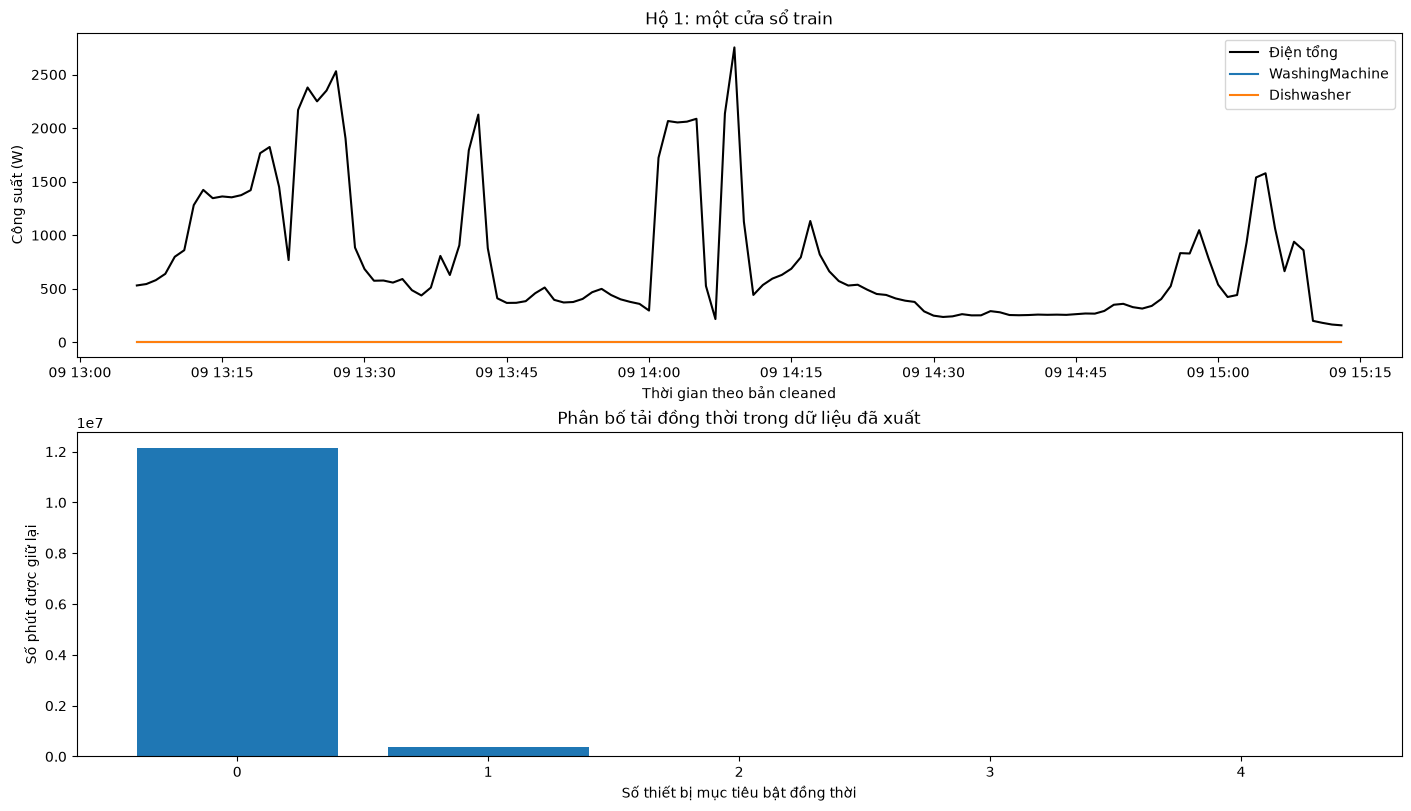

Tổng số cửa sổ theo tập:


,candidate_windows,kept_windows,dropped_windows
split,,,
test,24387,17981,6406
train,97844,80012,17832


In [9]:
assert example is not None, "Chưa có cửa sổ train để minh họa."
index = pd.date_range(pd.Timestamp(example["start_time_ns"][0]), periods=CONFIG["window_size"], freq="1min")
fig, axes = plt.subplots(2, 1, figsize=(14, 8), layout="constrained")
axes[0].plot(index, example["x"][0, 0] * CONFIG["power_scale_w"], label="Điện tổng", color="black")
for channel, name in enumerate(CONFIG["targets"]):
    if example["valid"][0, channel].any():
        axes[0].plot(index, example["power"][0, channel] * CONFIG["power_scale_w"], label=name)
axes[0].set(title=f"Hộ {example['house']}: một cửa sổ train", ylabel="Công suất (W)", xlabel="Thời gian theo bản cleaned")
axes[0].legend()
overlap = overlap_report.groupby("active_target_devices")["minutes"].sum()
axes[1].bar(overlap.index, overlap.values)
axes[1].set(xlabel="Số thiết bị mục tiêu bật đồng thời", ylabel="Số phút được giữ lại", title="Phân bố tải đồng thời trong dữ liệu đã xuất")
fig.savefig(OUTPUT_DIR / "data_preview.png", dpi=150)
plt.show()
print("Tổng số cửa sổ theo tập:")
display(house_report.groupby("split")[["candidate_windows", "kept_windows", "dropped_windows"]].sum())

## Thực hiện hai nhánh nghiên cứu

1. **Mô hình chung:** train trên các shard train của mọi hộ; báo metrics riêng trên shard test của từng hộ.
2. **Mỗi hộ một mô hình:** khởi tạo mới, train đúng shard train của hộ h; đánh giá đúng shard test của hộ h. Không khởi tạo từ mô hình chung, vì đó là thí nghiệm fine-tuning khác.

Chạy hai nhánh cho cả hai kiến trúc với cùng 5 seed trọng số; giữ seed dữ liệu 42. Với 20 hộ, kế hoạch là `(1 + 20) × 5 = 105` lần train/kiến trúc, tổng 210 lần cho hai kiến trúc. File `study_runs.json` chỉ là kế hoạch, chưa thực thi.

Không đưa `test_loader` vào đối số `val_loader`. Runner TwoStage lấy 20% thời gian cuối của phần train làm validation, dừng sớm theo validation và nạp checkpoint tốt nhất trước khi đánh giá test. Mốc 80/20 của CSV không đổi; tỷ lệ thời gian toàn kỳ xấp xỉ 64/16/20.

Khi đánh giá, luôn truyền mask `valid`, đổi công suất về W và lưu bảng `model × protocol × seed × house × device`. Báo trung bình và độ lệch chuẩn trên seed, sau đó tổng hợp theo hộ, kèm số mẫu hợp lệ và độ phủ nhãn. Không gọi score từ chia thời gian là khả năng tổng quát sang hộ chưa thấy. Mốc 80% áp dụng trên thời gian lịch trước khi lọc cửa sổ, không ép số cửa sổ hợp lệ đúng tỷ lệ 80/20.

Các artifact bản cũ chia theo hộ được giữ trong thư mục cũ và không được dùng lẫn với manifest thời gian mới.

Train chỉ cần import `REFITCSVDataset` từ `training.data`, chọn đúng thư mục manifest CSV và tạo DataLoader. Công suất được normalize tại loader; khi báo metrics nhân lại 10000 để về W. Dữ liệu NPZ cũ được giữ riêng làm artifact của các phiên bản trước, không dùng với manifest CSV mới.
